# MIST Isochrones

## Background

So like I was trying to explain, and how the [Wikipedia article](https://en.wikipedia.org/wiki/Stellar_isochrone) probably explained better, an isochrone at its core just represents the location of different stars of different masses but the same ages on an HR Diagram (analogous to the color-magnitude diagrams). Since stellar mass, age, luminosity, radius, etc., are all related, if you have an isochrone of an appropriate age, you can match a real star you have with an isochrone star based on magnitude, mass, or whatever quantity you may know about it. You can also use it to show the relationship between different properties, and what the theoretical values should be.  

[MIST](https://waps.cfa.harvard.edu/MIST/) uses stellar evolution models created with the [MESA](https://docs.mesastar.org/en/latest/) stellar modeling code. The details of that aren't really important, but context.

## For MISHAPS

First things first, I decided it was easier to put all the isochrones on Unity, so they're currently located at ```/fs/project/gaudi.1/crisp/mishaps/isochrones```. You'll notice there are three different photometric systems mentioned (DECam, PanSTARRS, and UBVRI, which is the standard Johnson-Cousins filter system), and if you go to any of those folders, you'll also notice that they're named as {mist version}\_feh\_{[Fe/H] value}\_{[alpha/Fe] value}\_{vvcrit version}\_{photometric system}.iso.cmd. Full disclosure, I don't actually know what the vvcrit means. The alpha/Fe value doesn't really matter, because they haven't actually added alpha abundances to the isochrones yet. In theory, you'd want to pick the isochrone file with the appropriate [Fe/H] value for the Bulge, but that's...a complicated choice to make, which we can talk about later. So for the purposes of this demo, I'm going to just arbitrarily pick [Fe/H] = 0.0. I'll also be using the PanSTARRS isochrone since, because you're trying to get the photometry into the PanSTARRS system, those isochrones should more accurately match the radii you end up with.

An important thing to note is that MIST doesn't include stellar radii by default, so in this notebook I'm going to go through how to load one of the isochrones, how to estimate the radii, and how to plot the radii as a function of magnitude. Also, the magnitudes are in **absolute** magnitude, so we'll also need to convert!

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
'''
This function takes the name of your isochrone file and a log(age), filters the isochrone file for the appropriate age, and calculates the stellar radii from the luminosity, temperature, etc.

The age of the bulge is another complicated question, but we've been using 10^10 years as the age. So log(age) should just be 10.
'''
def load_iso(isofile,logages_):
    # these are just column numbers
    cRadius=0
    cMass=3
    cMini=2
    cMI=13
    cMTESS=-2
    cMGaia=-5
    cLum=6
    cTeff=4
    cAge=1
    logages = logages_
    
    # if you want multiple ages, give them as a list and this will keep all of them. Otherwise just give a single one.
    if isinstance(logages_,list):
        logages = np.array(logages_)
    elif not isinstance(logages_,np.ndarray):
        logages = np.array([logages])
    
    # Load isochrone, skipping rows that just have comments
    iso = pd.read_csv(isofile, sep='\\s+', header=None, skiprows=13, engine='python', comment='#')
                                                                                            
    #Replace the idx column with the radii                                                                  
    iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))
            
    # this does the actual filtering for the age(s) you want
    ret = []
    for i, logage in enumerate(logages):
        ret.append(iso[(iso.iloc[:,-1] <= 4.0) & (np.abs(iso.iloc[:,cAge]-logage)<0.001)])
    if len(ret)==1:
        ret = ret[0]
    
    return ret

### Loading, Filtering, and adding the Radius

In [8]:
isofile = "/fs/project/gaudi.1/crisp/mishaps/isochrones/MIST_v1.2_vvcrit0.4_PanSTARRS/MIST_v1.2_feh_m3.00_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd"
logage = 10

In [7]:
iso = load_iso(isofile, logage)
iso_cols = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
            '[Fe/H]', 'PS_g', 'PS_r', 'PS_i', 'PS_z', 'PS_y', 'PS_w', 'PS_open', 'phase']
iso.columns = iso_cols

/tmp/slurmtmp.8809558/ipykernel_614870/629669663.py:29: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0         1.139883
1         1.151859
2         1.175650
3         1.199683
4         1.223905
           ...    
87038    31.238845
87039    31.702281
87040    31.958761
87041    32.831422
87042    33.757193
Length: 87043, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))


### Absolute to Apparent Magnitude

In [9]:
d = 8000 # distance to the Bulge in parsecs, this will be needed for converting to apparent magnitude

In [10]:
ps_iso_g = iso.loc[:,'PS_g'] + 5*np.log10(d) - 5
ps_iso_r = iso.loc[:,'PS_r'] + 5*np.log10(d) - 5
ps_iso_i = iso.loc[:,'PS_i'] + 5*np.log10(d) - 5
ps_iso_z = iso.loc[:,'PS_z'] + 5*np.log10(d) - 5

### ...and Plot Radius vs. Magnitude

Text(0, 0.5, 'Stellar Radius [R$_{\\odot}$]')

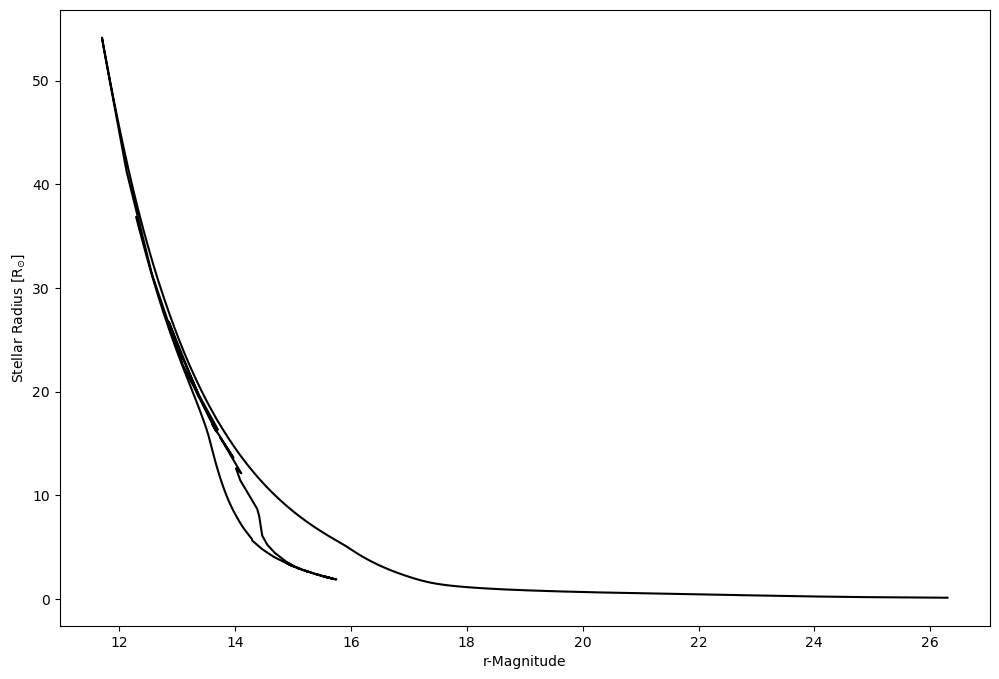

In [14]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(ps_iso_r, iso.loc[:,'Radius_Estimate'], 'k-')
ax.set_xlabel('r-Magnitude')
ax.set_ylabel(r'Stellar Radius [R$_{\odot}$]')

For MISHAPS data, we're really only going to care about *maybe* 17-22 (though 19-21 is more realistic). We also aren't going to care about the things that are more than a few solar radii, since those aren't likely to host planets. Plus, the physics gets a lot more complex when you go to much much larger radii, so we're less likely to have accurate estimates anyway. So, focus in on the bits we care about a bit...

(0.0, 3.0)

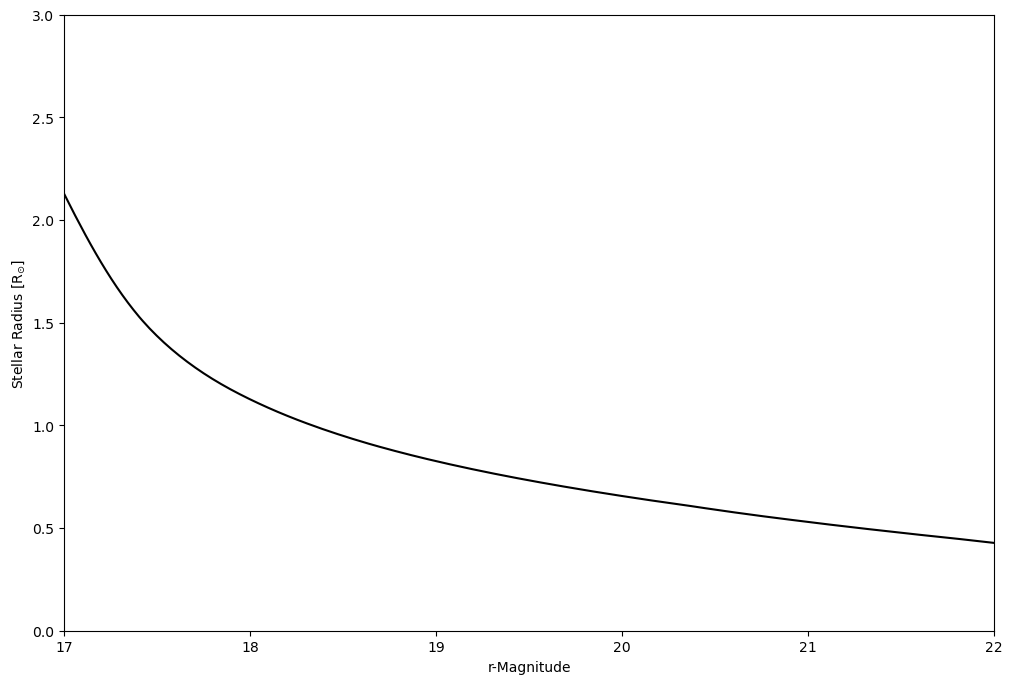

In [15]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(ps_iso_r, iso.loc[:,'Radius_Estimate'], 'k-')
ax.set_xlabel('r-Magnitude')
ax.set_xlim(17.0, 22.0)
ax.set_ylabel(r'Stellar Radius [R$_{\odot}$]')
ax.set_ylim(0.0, 3.0)

## CMD

Just to show what the CMD looks like for the PanSTARRS isochrones...

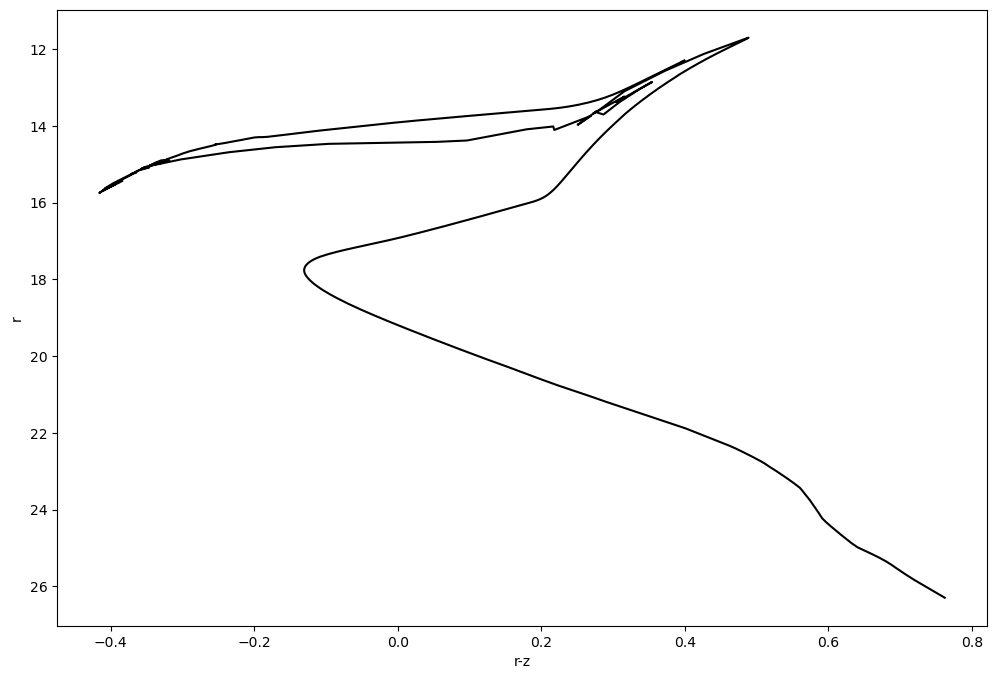

In [16]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(ps_iso_r-ps_iso_z, ps_iso_r, 'k-')
ax.set_xlabel('r-z')
ax.set_ylabel('r')
ax.invert_yaxis()